# Spectral convergence


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.function_library import gaussian, log_sum_exp, levy
from utilities.residual_orponet import ResidualOrPoNet
from utilities.training import Trainer


## 1. Settings


In [2]:
SEED = 42
DEVICE = torch.device("cpu")
DTYPE = torch.float64

torch.set_num_threads(1)


## 2. Train at each order


In [3]:
DIMENSION = 5
VALIDATION_SAMPLES = 4096


def make_model(degree, radius):
    model = ResidualOrPoNet(
        basis_configs=[
            {"type": "chebyshev", "degree": degree, "constant_channels": 2}
            for _ in range(DIMENSION)
        ],
        data_domain_lb=[-radius] * DIMENSION,
        data_domain_ub=[radius] * DIMENSION,
        training_domain_lb=[-1] * DIMENSION,
        training_domain_ub=[1] * DIMENSION,
        coeff_init_std=0.1,
        neuron_copies=1,
        normalize_basis=False,
        use_additive_basis_branch=True,
        gate_config=None,
        dtype=DTYPE,
    ).to(DEVICE)
    # Basis-aware initialization leaves additive weights unchanged. Retain the
    # source's fan-in Gaussian distribution for this branch explicitly.
    with torch.no_grad():
        for layer in model._hidden_layers[1:]:
            weight = layer.basis_projection
            weight.normal_(mean=0.0, std=weight.shape[0] ** -0.5)
    return model


def sample_data(target, radius, train_size):
    engine = torch.quasirandom.SobolEngine(DIMENSION, scramble=True, seed=1234)
    # The retained driver draws float32 Sobol points, then scales in float64.
    unit = engine.draw(train_size + VALIDATION_SAMPLES).double()
    inputs = (radius * (2 * unit - 1)).to(dtype=DTYPE, device=DEVICE)
    targets = target(inputs)
    return (
        inputs[:train_size],
        targets[:train_size],
        inputs[train_size:],
        targets[train_size:],
    )


In [4]:
EPOCHS = 500
RECORD_EVERY = 50


def best_recorded_mse(history):
    # Trainer also records epoch 1 and intermediate L-BFGS steps; exclude these
    # from selection to retain the paper driver's monitoring cadence.
    adam = history[history["stage"] == "adamw"]
    recorded_adam = adam[
        (adam["update"] % RECORD_EVERY == 0) | (adam["update"] == EPOCHS)
    ]
    lbfgs = history[history["stage"] == "lbfgs"].tail(1)
    errors = np.concatenate([recorded_adam["validation_mse"], lbfgs["validation_mse"]])
    if not np.isfinite(errors).all():
        raise FloatingPointError("Non-finite MSE in the order sweep.")
    return errors.min()


In [5]:
SAMPLE_PARAMETER_RATIO = 5
LBFGS_STEPS = 40


def train_order(target, radius, degree):
    torch.manual_seed(SEED + degree)
    model = make_model(degree, radius)
    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    train_size = int(np.ceil(SAMPLE_PARAMETER_RATIO * parameter_count))
    train_x, train_y, validation_x, validation_y = sample_data(
        target, radius, train_size
    )
    model.apply_basis_aware_init(train_x, gain=0.1)
    trainer = Trainer(
        model,
        (train_x, train_y),
        (validation_x, validation_y),
        target_stats=(train_y.mean(), train_y.std()),
        selection=None,
    )
    loader = DataLoader(
        TensorDataset(train_x, trainer.train_targets),
        batch_size=65536,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED + 1000 + degree),
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-6)
    trainer.fit(optimizer, epochs=EPOCHS, batches=loader, record_every=RECORD_EVERY)
    if LBFGS_STEPS > 0:
        optimizer = torch.optim.LBFGS(
            model.parameters(),
            lr=1.0,
            max_iter=20,
            history_size=100,
            tolerance_grad=1e-9,
            tolerance_change=1e-11,
            line_search_fn="strong_wolfe",
        )
        trainer.fit_lbfgs(optimizer, steps=LBFGS_STEPS)
    return best_recorded_mse(trainer.history)


In [6]:
# Entries are (name, target, physical-domain radius, polynomial orders).
problems = [
    ("Gaussian", gaussian, 2, [1, 2, 3, 4, 5, 6, 8, 10]),
    ("LogSumExp", log_sum_exp, 2, [1, 2, 3, 4, 5, 6, 8, 10]),
    ("Levy", levy, 5, [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20]),
]

results = {}
for name, target, radius, degrees in problems:
    errors = []
    for degree in degrees:
        error = train_order(target, radius, degree)
        errors.append(error)
        print(f"{name}, order {degree}: best validation MSE = {error:.3e}", flush=True)
    results[name] = {"degree": np.array(degrees), "mse": np.array(errors)}


Gaussian, order 1: best validation MSE = 1.516e+00


Gaussian, order 2: best validation MSE = 7.390e-02


Gaussian, order 3: best validation MSE = 7.572e-02


Gaussian, order 4: best validation MSE = 1.343e-03


Gaussian, order 5: best validation MSE = 1.281e-03


Gaussian, order 6: best validation MSE = 1.507e-05


... (19 outputs left out)

Levy, order 14: best validation MSE = 2.027e-03


Levy, order 16: best validation MSE = 1.077e-03


Levy, order 18: best validation MSE = 1.756e-04


Levy, order 20: best validation MSE = 1.424e-05


## 3. Order convergence


In [7]:
def exponential_fit(degrees, errors, name):
    degrees, errors = np.asarray(degrees), np.asarray(errors)
    if np.any(errors <= 0) or not np.isfinite(errors).all():
        raise ValueError("Exponential fitting requires finite positive MSE.")
    if name == "LogSumExp":
        fit_mask = degrees <= 4
        fit_degrees, fit_errors = degrees[fit_mask], errors[fit_mask]
    else:
        fit_end = max(int(np.argmin(errors)) + 1, min(4, len(degrees)))
        fit_degrees, fit_errors = degrees[:fit_end], errors[:fit_end]
    if len(fit_degrees) < 2:
        raise ValueError("At least two orders are required for an exponential fit.")
    slope, intercept = np.polyfit(fit_degrees, np.log(fit_errors), 1)
    return fit_degrees, np.exp(intercept + slope * fit_degrees), -slope


def plot_convergence(ax, name):
    degrees, errors = results[name]["degree"], results[name]["mse"]
    if name == "LogSumExp":
        mask = degrees <= 5
        degrees, errors = degrees[mask], errors[mask]
    fit_degrees, fitted_errors, alpha = exponential_fit(degrees, errors, name)
    ax.semilogy(degrees, errors, "o-", color="#1f77b4", linewidth=1.35, markersize=3.8)
    if alpha > 0:
        ax.semilogy(fit_degrees, fitted_errors, "--", color="red", linewidth=1.35)
        ax.text(
            0.5,
            0.78,
            rf"$Ce^{{-{alpha:.2f}p}}$",
            transform=ax.transAxes,
            color="red",
            fontsize=10,
        )
    else:
        ax.text(0.5, 0.78, "No fitted decay", transform=ax.transAxes, fontsize=10)
    ax.set(title=name, xlabel="Order $p$")
    ax.set_xticks([1, 4, 8, 12, 16, 20] if name == "Levy" else degrees)
    ax.grid(True, alpha=0.25)


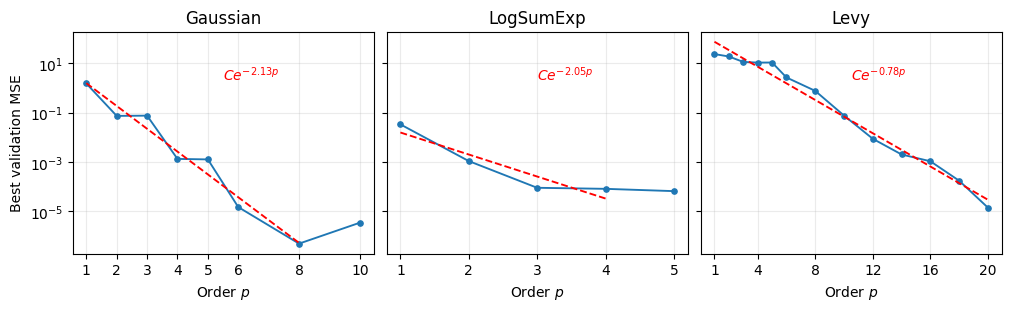

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True, constrained_layout=True)
plot_convergence(axes[0], "Gaussian")
axes[0].set_ylabel("Best validation MSE")
plot_convergence(axes[1], "LogSumExp")
plot_convergence(axes[2], "Levy")
plt.show()
